R04

R04: full fine-tuning + augmentation (random crop, flips, colour jitter) | 11,186,772 trainable weights
  epoch  1 | lr 1.00e-02 | train loss 0.212 acc 0.926 | val_lab F1-16 0.950 | val_wild F1-16 0.428 * | 97 s
  epoch  2 | lr 9.89e-03 | train loss 0.075 acc 0.974 | val_lab F1-16 0.967 | val_wild F1-16 0.437 * | 32 s
  epoch  3 | lr 9.57e-03 | train loss 0.053 acc 0.982 | val_lab F1-16 0.969 | val_wild F1-16 0.441 * | 32 s
  epoch  4 | lr 9.05e-03 | train loss 0.043 acc 0.985 | val_lab F1-16 0.961 | val_wild F1-16 0.435 | 33 s
  epoch  5 | lr 8.35e-03 | train loss 0.032 acc 0.989 | val_lab F1-16 0.977 | val_wild F1-16 0.412 | 34 s
  epoch  6 | lr 7.50e-03 | train loss 0.024 acc 0.992 | val_lab F1-16 0.972 | val_wild F1-16 0.430 | 34 s
  epoch  7 | lr 6.55e-03 | train loss 0.021 acc 0.993 | val_lab F1-16 0.981 | val_wild F1-16 0.420 | 35 s
  epoch  8 | lr 5.52e-03 | train loss 0.015 acc 0.996 | val_lab F1-16 0.979 | val_wild F1-16 0.421 | 34 s
  early stop: no val_wild improvement for 

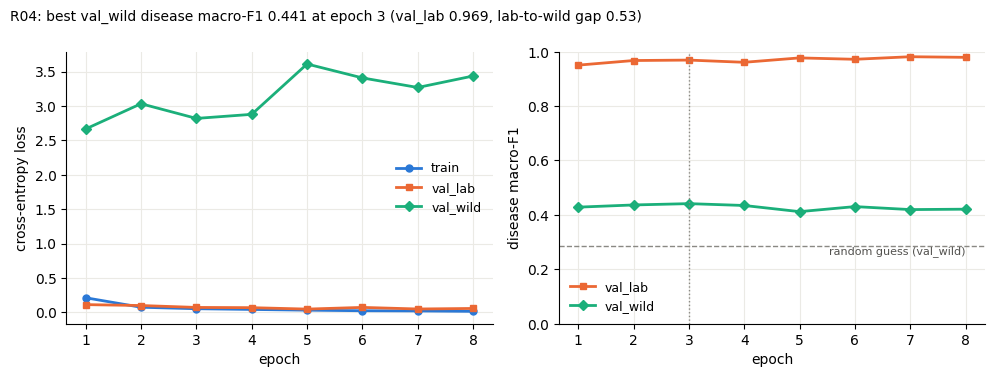

In [1]:
from plantdata import load_classes, read_manifest
from pathlib import Path
from training import run_experiment
from plots import plot_history

SPLITS_DIR = Path("splits_v2")
CACHE_DIR = Path("cache_256")
CLASS_IDS, CROPS, crop_mask = load_classes(SPLITS_DIR)
manifest = read_manifest(CACHE_DIR)

summary, history = run_experiment(
    "R04", "full fine-tuning + augmentation (random crop, flips, colour jitter)",
    manifest, CACHE_DIR, CLASS_IDS, CROPS, crop_mask,
    depth=18, freeze="none", augment=True, optimiser="sgd", lr=0.01, weight_decay=1e-4,
    batch_size=64, epochs=15, patience=5, seed=42)

plot_history("R04");

R05, R06, R07, R08, R09, R10

In [ ]:
SWEEP = [
    ("R05", "sgd",   0.001, 1e-4, "LR sweep: SGD lr 0.001"),
    ("R06", "sgd",   0.003, 1e-4, "LR sweep: SGD lr 0.003"),
    ("R07", "sgd",   0.03,  1e-4, "LR sweep: SGD lr 0.03"),
    ("R08", "adamw", 1e-4,  0.01, "LR sweep: AdamW lr 1e-4"),
    ("R09", "adamw", 3e-4,  0.01, "LR sweep: AdamW lr 3e-4"),
    ("R10", "adamw", 1e-3,  0.01, "LR sweep: AdamW lr 1e-3"),
]
for run_id, opt, lr, wd, note in SWEEP:
    run_experiment(run_id, note, manifest, CACHE_DIR, CLASS_IDS, CROPS, crop_mask,
                   depth=18, freeze="none", augment=True, optimiser=opt, lr=lr, weight_decay=wd,
                   batch_size=64, epochs=15, patience=5, seed=42)

R05: LR sweep: SGD lr 0.001 | 11,186,772 trainable weights
  epoch  1 | lr 1.00e-03 | train loss 0.508 acc 0.833 | val_lab F1-16 0.901 | val_wild F1-16 0.428 * | 99 s
  epoch  2 | lr 9.89e-04 | train loss 0.155 acc 0.955 | val_lab F1-16 0.942 | val_wild F1-16 0.459 * | 31 s
  epoch  3 | lr 9.57e-04 | train loss 0.100 acc 0.970 | val_lab F1-16 0.954 | val_wild F1-16 0.466 * | 31 s
  epoch  4 | lr 9.05e-04 | train loss 0.081 acc 0.974 | val_lab F1-16 0.958 | val_wild F1-16 0.469 * | 33 s
  epoch  5 | lr 8.35e-04 | train loss 0.067 acc 0.980 | val_lab F1-16 0.962 | val_wild F1-16 0.465 | 34 s
  epoch  6 | lr 7.50e-04 | train loss 0.058 acc 0.982 | val_lab F1-16 0.966 | val_wild F1-16 0.462 | 34 s
  epoch  7 | lr 6.55e-04 | train loss 0.052 acc 0.984 | val_lab F1-16 0.972 | val_wild F1-16 0.461 | 34 s
  epoch  8 | lr 5.52e-04 | train loss 0.051 acc 0.983 | val_lab F1-16 0.970 | val_wild F1-16 0.463 | 34 s
  epoch  9 | lr 4.48e-04 | train loss 0.046 acc 0.985 | val_lab F1-16 0.969 | val_wil

In [ ]:
import pandas as pd
cols = ["run_id", "note", "freeze", "augment", "optimiser", "lr", "batch_size", "depth", "best_epoch",
        "val_lab_f1_16", "val_wild_f1_16", "val_wild_late_blight_recall", "train_minutes"]

pd.read_csv("results/runs_summary.csv")[cols].round(
    {"val_lab_f1_16": 3, "val_wild_f1_16": 3, "val_wild_late_blight_recall": 3, "train_minutes": 1})

,run_id,note,freeze,augment,optimiser,lr,batch_size,depth,best_epoch,val_lab_f1_16,val_wild_f1_16,val_wild_late_blight_recall,train_minutes
0,R01,"initial ANN: ResNet-18, frozen backbone (head ...",backbone,False,sgd,0.010,64,18,3,0.923,0.359,0.829,3.164
1,R02,fine-tune stage 4 + head (stem and stages 1-3 ...,stages1-3,False,sgd,0.010,64,18,10,0.979,0.403,0.802,12.392
2,R03,full fine-tuning (all layers),none,False,sgd,0.010,64,18,6,0.986,0.445,0.704,16.301
3,R04,"full fine-tuning + augmentation (random crop, ...",none,True,sgd,0.010,64,18,3,0.969,0.441,0.665,5.533
4,R05,LR sweep: SGD lr 0.001,none,True,sgd,0.001,64,18,4,0.958,0.469,0.720,6.081
5,R06,LR sweep: SGD lr 0.003,none,True,sgd,0.003,64,18,3,0.968,0.450,0.740,5.307
6,R07,LR sweep: SGD lr 0.03,none,True,sgd,0.030,64,18,4,0.956,0.451,0.668,16.126
7,R08,LR sweep: AdamW lr 1e-4,none,True,adamw,0.000,64,18,4,0.971,0.441,0.650,6.071
8,R09,LR sweep: AdamW lr 3e-4,none,True,adamw,0.000,64,18,3,0.951,0.447,0.705,5.392
9,R10,LR sweep: AdamW lr 1e-3,none,True,adamw,0.001,64,18,2,0.923,0.440,0.638,4.796
